In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_excel("/content/drive/MyDrive/Week4_dataset/Consumer_Complaints.xlsx")

# Inspect dataset
print(df.shape)

df.head()

(62516, 12)


,Complaint ID,Submitted via,Date submitted,Date received,State,Product,Sub-product,Issue,Sub-issue,Company public response,Company response to consumer,Timely response?
0,4848023,Referral,2021-10-24,2021-10-27,NY,Mortgage,Conventional home mortgage,Applying for a mortgage or refinancing an exis...,NaN,Company has responded to the consumer and the ...,Closed with explanation,Yes
1,3621464,Web,2020-04-24,2020-04-24,FL,"Money transfer, virtual currency, or money ser...",Refund anticipation check,Lost or stolen check,NaN,Company has responded to the consumer and the ...,Closed with monetary relief,Yes
2,5818349,Web,2022-07-27,2022-07-27,CA,"Credit reporting, credit repair services, or o...",Credit reporting,Incorrect information on your report,Account information incorrect,Company has responded to the consumer and the ...,Closed with explanation,Yes
3,7233015,Referral,2023-07-10,2023-07-11,CA,Credit card or prepaid card,General-purpose prepaid card,Problem getting a card or closing an account,"Trouble getting, activating, or registering a ...",NaN,In progress,NaN
4,5820224,Referral,2022-07-27,2022-07-28,VA,Credit card or prepaid card,General-purpose credit card or charge card,Closing your account,Company closed your account,Company has responded to the consumer and the ...,Closed with explanation,Yes


1.Conducting exploratory data analysis

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62516 entries, 0 to 62515
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   Complaint ID                  62516 non-null  int64         
 1   Submitted via                 62516 non-null  object        
 2   Date submitted                62516 non-null  datetime64[ns]
 3   Date received                 62516 non-null  datetime64[ns]
 4   State                         62516 non-null  object        
 5   Product                       62516 non-null  object        
 6   Sub-product                   62509 non-null  object        
 7   Issue                         62516 non-null  object        
 8   Sub-issue                     51658 non-null  object        
 9   Company public response       60341 non-null  object        
 10  Company response to consumer  62516 non-null  object        
 11  Timely response?            

In [30]:
df.describe()

,Complaint ID,Date submitted,Date received
count,6.251600e+04,62516,62516
mean,4.512642e+06,2020-11-24 16:07:14.883869696,2020-11-25 21:31:05.071341568
min,2.471340e+06,2017-05-01 00:00:00,2017-05-01 00:00:00
25%,3.254020e+06,2019-05-22 00:00:00,2019-05-28 00:00:00
50%,4.178582e+06,2021-03-02 00:00:00,2021-03-03 00:00:00
75%,5.771284e+06,2022-07-14 00:00:00,2022-07-15 00:00:00
max,7.458912e+06,2023-08-28 00:00:00,2023-08-28 00:00:00
std,1.442917e+06,NaN,NaN


In [31]:
df.isnull().sum()

,0
Complaint ID,0
Submitted via,0
Date submitted,0
Date received,0
State,0
Product,0
Sub-product,7
Issue,0
Sub-issue,10858
Company public response,2175


In [32]:
df.duplicated().sum()

np.int64(0)

2.Analysing annual and monthly complaint distributions

In [33]:
df['Year'] = df['Date submitted'].dt.year

df['Month'] = df['Date submitted'].dt.month

df['Month_Name'] = df['Date submitted'].dt.month_name()

In [34]:
annual_complaints = df['Year'].value_counts().sort_index()

print(annual_complaints)

Year
2017     5394
2018     7872
2019     7075
2020     8942
2021    11149
2022    12953
2023     9131
Name: count, dtype: int64


In [35]:
monthly_complaints = df['Month'].value_counts().sort_index()

print(monthly_complaints)

Month
1     4883
2     4602
3     5335
4     5386
5     5608
6     5575
7     6474
8     5684
9     4765
10    4902
11    4626
12    4676
Name: count, dtype: int64


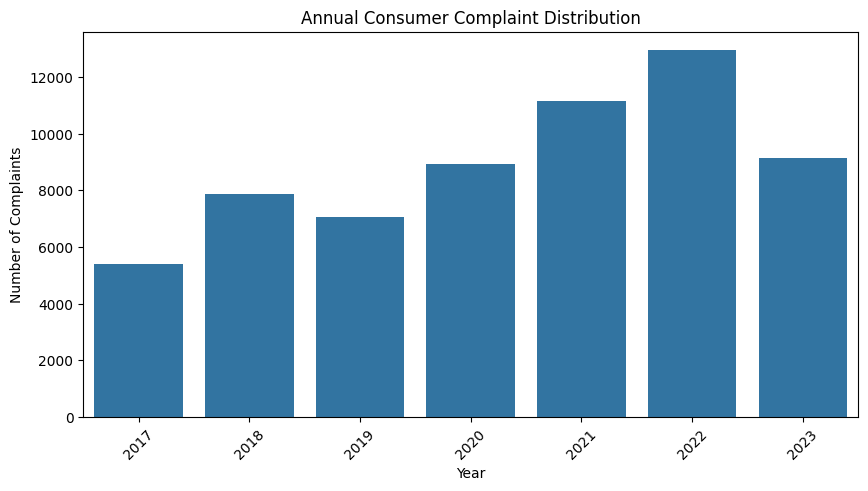

In [36]:
# Annual distribution plot
plt.figure(figsize=(10, 5))

sns.barplot(
    x=annual_complaints.index,
    y=annual_complaints.values
)

plt.title('Annual Consumer Complaint Distribution')
plt.xlabel('Year')
plt.ylabel('Number of Complaints')
plt.xticks(rotation=45)
plt.show()

The annual complaint distribution indicates an overall upward trend in consumer complaints between 2017 and 2022. The highest complaint volume was observed in 2022, with 12,953 complaints. Although a decline was observed in 2019, complaint numbers increased consistently from 2020 onwards. The lower count in 2023 should be interpreted cautiously because the dataset covers only January to August. These changes may reflect variations in consumer experiences, reporting behaviour, financial service activity, or other external factors. The observed increase in complaint volume does not necessarily indicate a corresponding increase in the actual rate of consumer dissatisfaction.

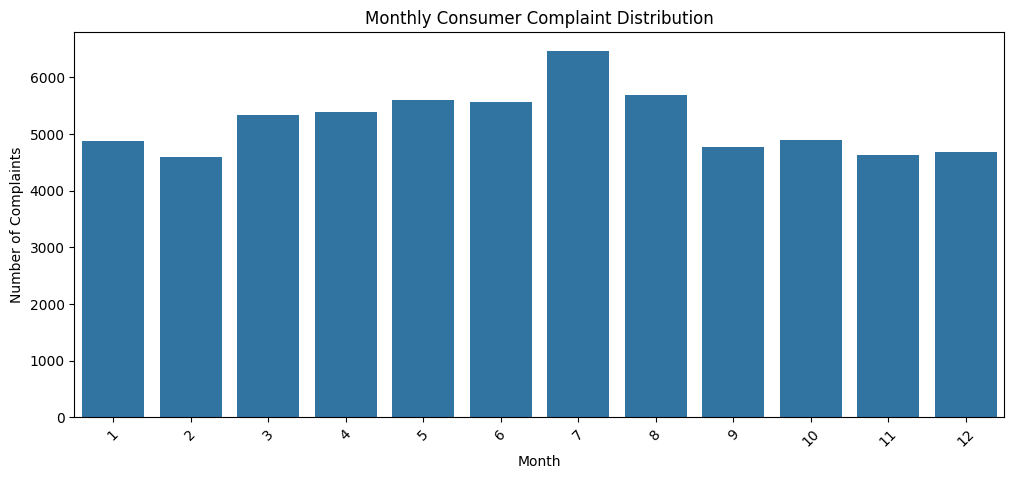

In [37]:
# Monthly bar chart
plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_complaints.index,
    y=monthly_complaints.values
)

plt.title('Monthly Consumer Complaint Distribution')
plt.xlabel('Month')
plt.ylabel('Number of Complaints')
plt.xticks(rotation=45)

plt.show()

The monthly complaint distribution shows that July recorded the highest number of complaints (6,474), while February recorded the lowest (4,602). May, June and August also showed relatively high complaint volumes. However, these figures represent aggregated counts across the entire observation period. Since the dataset does not cover complete calendar years at both ends, further analysis using complete years is required before drawing conclusions about seasonal complaint patterns.

3. Identifying frequently reported products and issues.

In [38]:
product_counts = df['Product'].value_counts()

print(product_counts)

Product
Checking or savings account                                                     24814
Credit card or prepaid card                                                     16197
Credit reporting, credit repair services, or other personal consumer reports     7710
Mortgage                                                                         6601
Money transfer, virtual currency, or money service                               3453
Debt collection                                                                  2736
Vehicle loan or lease                                                             633
Payday loan, title loan, or personal loan                                         333
Student loan                                                                       39
Name: count, dtype: int64


In [39]:
issue_counts = df['Issue'].value_counts().head(10)

print(issue_counts)

Issue
Managing an account                                                                 15109
Incorrect information on your report                                                 4931
Problem with a purchase shown on your statement                                      4415
Closing an account                                                                   2953
Trouble during payment process                                                       2827
Opening an account                                                                   2725
Problem with a lender or other company charging your account                         2493
Fraud or scam                                                                        1987
Struggling to pay mortgage                                                           1904
Problem with a credit reporting company's investigation into an existing problem     1876
Name: count, dtype: int64


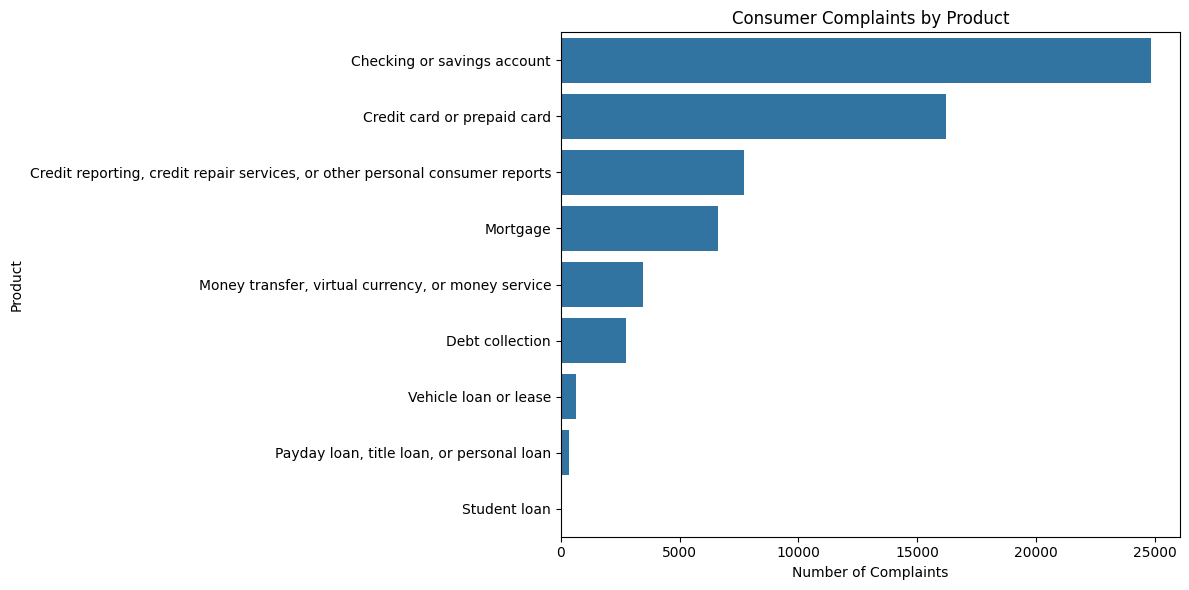

In [40]:
#product wise complaints
plt.figure(figsize=(12, 6))

product_counts = df['Product'].value_counts()

sns.barplot(
    x=product_counts.values,
    y=product_counts.index
)

plt.title('Consumer Complaints by Product')
plt.xlabel('Number of Complaints')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

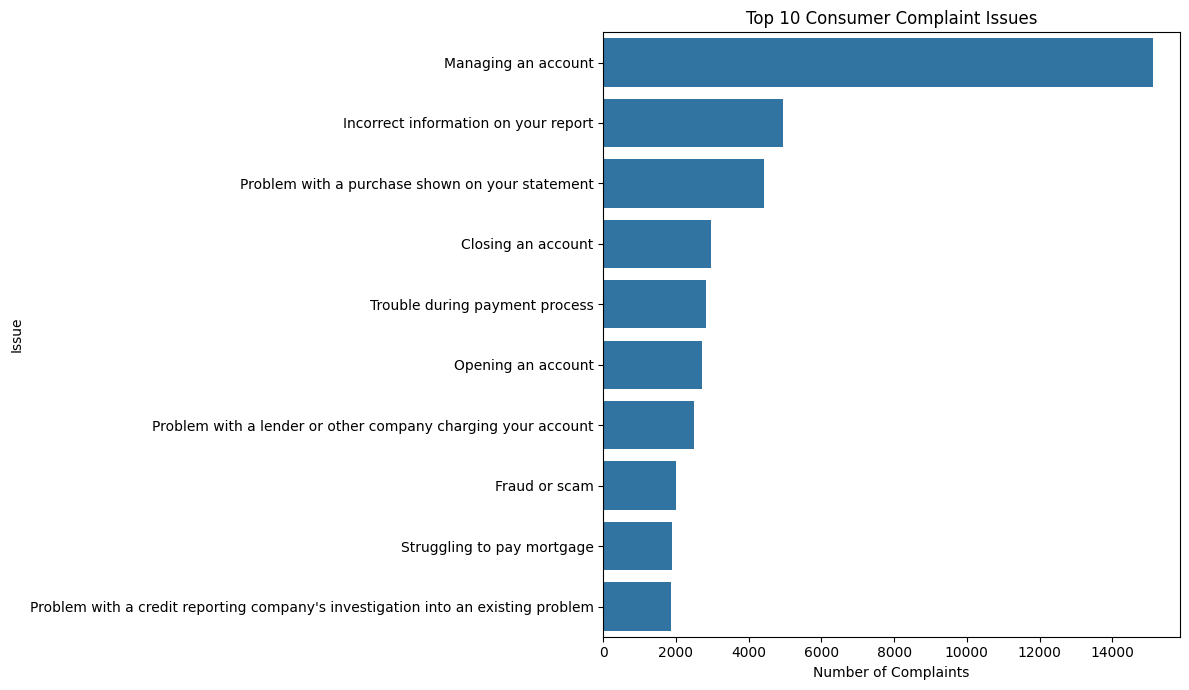

In [41]:
# Top 10 reported issues
plt.figure(figsize=(12, 7))

issue_counts = df['Issue'].value_counts().head(10)

sns.barplot(
    x=issue_counts.values,
    y=issue_counts.index
)

plt.title('Top 10 Consumer Complaint Issues')
plt.xlabel('Number of Complaints')
plt.ylabel('Issue')
plt.tight_layout()
plt.show()

The product-wise analysis revealed that checking or savings accounts generated the highest number of complaints, followed by credit cards and credit reporting services. Together, checking/savings accounts and credit cards represented approximately 65.6% of all complaints. The issue-wise analysis showed that account management was the most frequently reported concern, with 15,109 complaints. These findings indicate that everyday banking operations and account management deserve further investigation.

4.Investigating how complaint patterns have changed over time

In [42]:
year_product = pd.crosstab(
    df['Year'],
    df['Product']
)

print(year_product)

Product  Checking or savings account  Credit card or prepaid card  \
Year                                                                
2017                            2039                         1125   
2018                            3176                         1804   
2019                            3080                         1789   
2020                            3242                         2552   
2021                            4006                         3084   
2022                            5186                         3445   
2023                            4085                         2398   

Product  Credit reporting, credit repair services, or other personal consumer reports  \
Year                                                                                    
2017                                                   466                              
2018                                                   761                              
2019                  

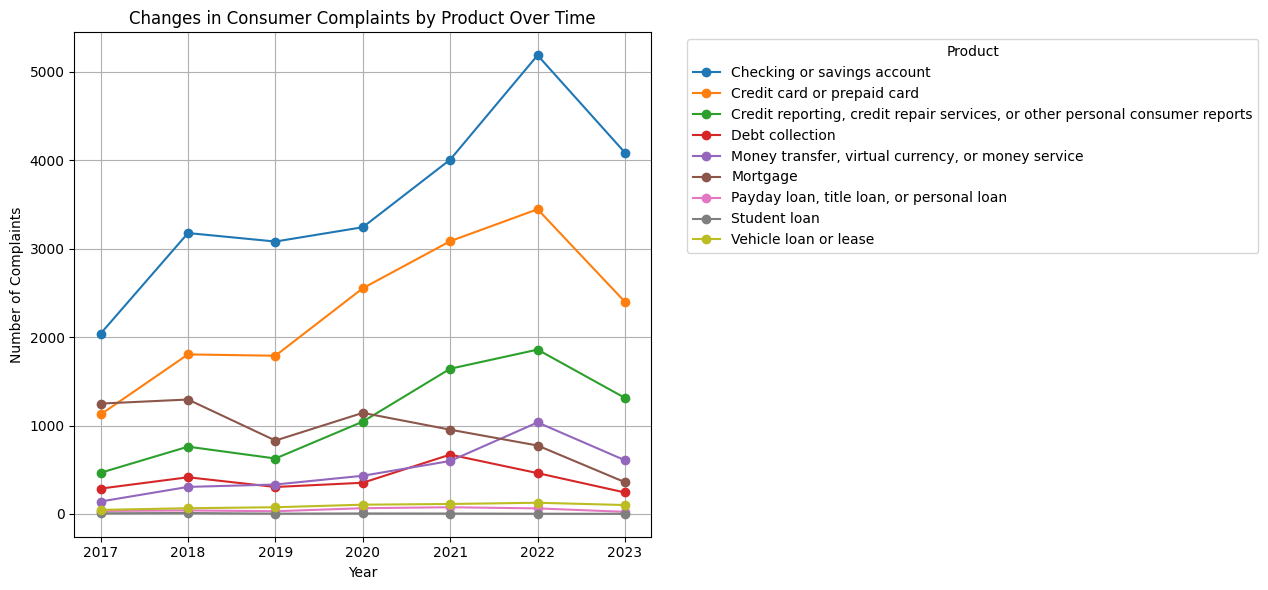

In [43]:
year_product.plot(
    kind='line',
    marker='o',
    figsize=(13, 6)
)

plt.title('Changes in Consumer Complaints by Product Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Complaints')
plt.xticks(year_product.index)
plt.legend(title='Product', bbox_to_anchor=(1.05, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

The year-wise product analysis reveals variations in consumer complaint patterns across different financial products. Checking or savings accounts consistently accounted for the highest complaint volumes, followed by credit cards. Both categories experienced substantial growth up to 2022. Credit reporting complaints also increased considerably during the later years of the observation period. In contrast, mortgage complaints showed an overall declining trend after 2018. Money transfer complaints experienced a noticeable increase in 2022. These findings suggest that consumer concerns varied across financial service categories over time. However, the decline observed in 2023 should be interpreted cautiously because the dataset covers only part of that year.

5.Examining the distribution of recorded company responses.

In [44]:
response_counts = df['Company response to consumer'].value_counts(dropna=False)

print(response_counts)

Company response to consumer
Closed with explanation            41044
Closed with monetary relief        14697
Closed with non-monetary relief     5273
In progress                         1494
Closed                                 8
Name: count, dtype: int64


In [45]:
response_percentages = (
    df['Company response to consumer']
    .value_counts(normalize=True, dropna=False) * 100
)

print(response_percentages.round(2))

Company response to consumer
Closed with explanation            65.65
Closed with monetary relief        23.51
Closed with non-monetary relief     8.43
In progress                         2.39
Closed                              0.01
Name: proportion, dtype: float64


In [46]:
public_response_counts = df['Company public response'].value_counts(dropna=False)

print(public_response_counts)

Company public response
Company has responded to the consumer and the CFPB and chooses not to provide a public response                            60311
NaN                                                                                                                         2175
Company believes the complaint provided an opportunity to answer consumer's questions                                         12
Company believes the complaint is the result of a misunderstanding                                                             7
Company believes it acted appropriately as authorized by contract or law                                                       6
Company believes complaint caused principally by actions of third party outside the control or direction of the company        3
Company disputes the facts presented in the complaint                                                                          2
Name: count, dtype: int64


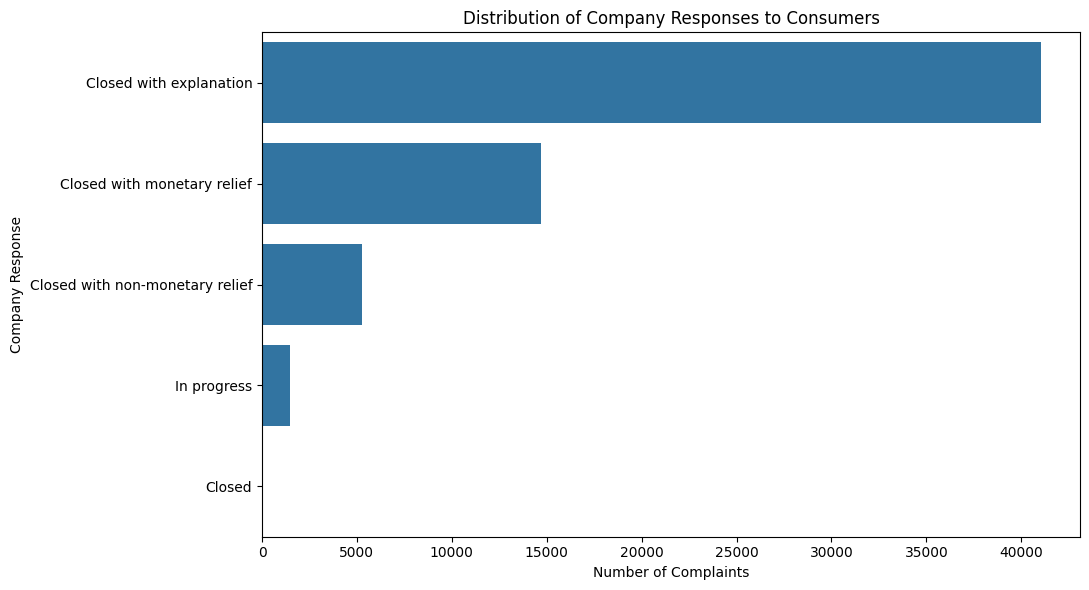

In [47]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    y='Company response to consumer',
    order=df['Company response to consumer'].value_counts().index
)

plt.title('Distribution of Company Responses to Consumers')
plt.xlabel('Number of Complaints')
plt.ylabel('Company Response')
plt.tight_layout()
plt.show()

The analysis of company public responses revealed that 96.47% of complaints were associated with companies that responded to the consumer and CFPB but chose not to provide a public response. Approximately 3.48% of records contained missing public-response information. Other categories, such as misunderstandings, contractual justifications and disputes over complaint facts, represented very small proportions. This indicates that public-facing explanations were rarely recorded in the dataset, although companies generally had a recorded response to consumers. The results should not be interpreted as evidence that companies failed to address complaints privately.

6. Analysing complaint-forwarding intervals

In [48]:
df['Forwarding_Days'] = (
    df['Date received'] - df['Date submitted']
).dt.days

print(df['Forwarding_Days'].describe())

count    62516.000000
mean         1.224886
std          5.649298
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        275.000000
Name: Forwarding_Days, dtype: float64


In [49]:
print("Negative intervals:",
      (df['Forwarding_Days'] < 0).sum())

print("Zero-day intervals:",
      (df['Forwarding_Days'] == 0).sum())

print("Missing intervals:",
      df['Forwarding_Days'].isnull().sum())

Negative intervals: 0
Zero-day intervals: 49634
Missing intervals: 0


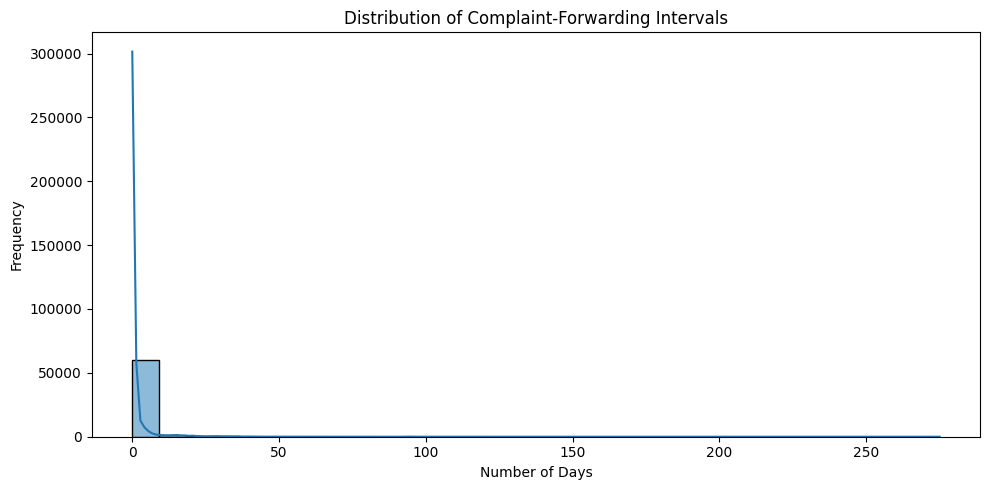

In [50]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Forwarding_Days'].dropna(),
    bins=30,
    kde=True
)

plt.title('Distribution of Complaint-Forwarding Intervals')
plt.xlabel('Number of Days')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


The analysis of complaint date intervals revealed that 79.40% of complaints had identical submission and received dates, while 20.60% had a positive interval. No negative or missing intervals were identified. This indicates that most complaints had matching recorded dates, although a proportion had a delay between the two dates. Further examination of the positive intervals is necessary to understand the distribution and identify unusually long intervals.

In [51]:
print(df['Forwarding_Days'].describe())


count    62516.000000
mean         1.224886
std          5.649298
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        275.000000
Name: Forwarding_Days, dtype: float64


In [52]:
positive_intervals = df.loc[
    df['Forwarding_Days'] > 0,
    'Forwarding_Days'
]

print(positive_intervals.describe())

count    12882.000000
mean         5.944341
std         11.262054
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max        275.000000
Name: Forwarding_Days, dtype: float64


7.Formulating research questions and hypothesis


RQ1

Is complaint volume associated with the financial product category?

Chi-square test of independence

RQ2

Is company response associated with the product category?

Chi-square test of independence


RQ3


Do positive date intervals differ across product categories?

Kruskal–Wallis test


RQ4

Is the distribution of company responses associated with the year of complaint submission?

Chi-square test of independence

8.Applying appropriate statistical tests where assumptions are satisfied.

In [53]:
# RQ1: Is complaint volume associated with financial product category across years?
# Hypotheses
# - H0: Product category and complaint year are independent.
# - H1: Product category and complaint year are associated.
from scipy.stats import chi2_contingency

# Create contingency table
rq1_table = pd.crosstab(
    df['Year'],
    df['Product']
)

print(rq1_table)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(rq1_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Minimum expected frequency:", expected.min())
print("Expected frequencies below 5:", (expected < 5).sum())

Product  Checking or savings account  Credit card or prepaid card  \
Year                                                                
2017                            2039                         1125   
2018                            3176                         1804   
2019                            3080                         1789   
2020                            3242                         2552   
2021                            4006                         3084   
2022                            5186                         3445   
2023                            4085                         2398   

Product  Credit reporting, credit repair services, or other personal consumer reports  \
Year                                                                                    
2017                                                   466                              
2018                                                   761                              
2019                  

In [54]:
import numpy as np

n = rq1_table.to_numpy().sum()
minimum_dimension = min(rq1_table.shape) - 1

cramers_v = np.sqrt(
    chi2 / (n * minimum_dimension)
)

print("Cramer's V:", cramers_v)

Cramer's V: 0.08810849337173333


A Chi-square test of independence was conducted to examine the association between complaint submission year and financial product category. The test showed a statistically significant association, χ²(48) = 2911.91, p < 0.001. Cramér's V was 0.0881, indicating a very weak association. Although complaint distributions across product categories differed statistically over the years, the strength of this relationship was small. This suggests that year and product category are associated, but the year-wise differences in product distribution are relatively modest in overall association terms.

In [55]:
# RQ2: Is company response associated with financial product category?
# H₀ (Null Hypothesis): The company's response does not depend on the type of financial product.
# H₁ (Alternative Hypothesis): The company's response differs depending on the type of financial product.

rq2_table = pd.crosstab(
    df['Product'],
    df['Company response to consumer']
)

chi2, p_value, dof, expected = chi2_contingency(rq2_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Minimum expected frequency:", expected.min())
print("Expected frequencies below 5:", (expected < 5).sum())

Chi-square statistic: 5574.765514799262
P-value: 0.0
Degrees of freedom: 32
Minimum expected frequency: 0.004990722375071982
Expected frequencies below 5: 11


In [56]:
print(df['Company response to consumer'].value_counts())


Company response to consumer
Closed with explanation            41044
Closed with monetary relief        14697
Closed with non-monetary relief     5273
In progress                         1494
Closed                                 8
Name: count, dtype: int64


In [57]:
df['Response_Grouped'] = df['Company response to consumer'].replace({
    'Closed': 'Closed without specified relief',
    'Closed with explanation': 'Closed without specified relief'
})

print(df['Response_Grouped'].value_counts())

Response_Grouped
Closed without specified relief    41052
Closed with monetary relief        14697
Closed with non-monetary relief     5273
In progress                         1494
Name: count, dtype: int64


In [58]:
rq2_table = pd.crosstab(
    df['Product'],
    df['Response_Grouped']
)

chi2, p_value, dof, expected = chi2_contingency(rq2_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Minimum expected frequency:", expected.min())
print("Expected frequencies below 5:", (expected < 5).sum())

Chi-square statistic: 5565.172738690671
P-value: 0.0
Degrees of freedom: 24
Minimum expected frequency: 0.9320174035446925
Expected frequencies below 5: 2


In [59]:
import numpy as np

n = rq2_table.to_numpy().sum()
minimum_dimension = min(rq2_table.shape) - 1

cramers_v = np.sqrt(
    chi2 / (n * minimum_dimension)
)

print("Cramer's V:", cramers_v)

Cramer's V: 0.17225946970150013


A Chi-square test was conducted to investigate the association between financial product category and company response to consumers. The initial result indicated a statistically significant association, χ²(24) = 5565.17, p < 0.001. Cramér's V was 0.1723, indicating a weak association. This suggests that company response patterns vary across financial product categories, although the strength of the relationship is relatively weak. However, the expected-frequency assumption was not fully satisfied, so the result should be interpreted cautiously and confirmed using an appropriate alternative method.

In [60]:
# RQ3: Do complaint date intervals differ across financial product categories?
# - H₀ (Null): The complaint date intervals are similar across all financial product categories.
# - H₁ (Alternative): The complaint date intervals differ for at least one financial product category.
positive_df = df[df['Forwarding_Days'] > 0].copy()

print(positive_df.shape)
print(positive_df['Product'].value_counts())

(12882, 17)
Product
Checking or savings account                                                     6414
Credit card or prepaid card                                                     2909
Mortgage                                                                        1857
Credit reporting, credit repair services, or other personal consumer reports     626
Debt collection                                                                  428
Money transfer, virtual currency, or money service                               410
Vehicle loan or lease                                                            124
Payday loan, title loan, or personal loan                                        101
Student loan                                                                      13
Name: count, dtype: int64


In [61]:
from scipy.stats import kruskal

groups = [
    group['Forwarding_Days'].values
    for name, group in positive_df.groupby('Product')
]

statistic, p_value = kruskal(*groups)

print("Kruskal-Wallis statistic:", statistic)
print("P-value:", p_value)
print("Number of product groups:", len(groups))

Kruskal-Wallis statistic: 424.9959622351603
P-value: 8.38220203668846e-87
Number of product groups: 9


In [62]:
n = len(positive_df)
k = len(groups)

epsilon_squared = (statistic - k + 1) / (n - k)

print("Epsilon squared:", epsilon_squared)

Epsilon squared: 0.03239306783462754


A Kruskal-Wallis test was conducted to determine whether positive recorded date intervals differed across financial product categories. The results showed a statistically significant difference, H(8) = 424.996, p < 0.001. The effect size, measured using epsilon-squared, was 0.0324, indicating a small effect. This suggests that although the recorded date intervals vary across product categories, the overall magnitude of the difference is relatively small. Further pairwise comparisons would be needed to identify which specific product categories differ.

In [64]:
# RQ4: Is company response associated with the year of complaint submission?
# H₀: Company response patterns do not differ across years.
# H₁: Company response patterns differ across years.
rq4_table = pd.crosstab(
    df['Year'],
    df['Company response to consumer']
)

chi2, p_value, dof, expected = chi2_contingency(rq4_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Minimum expected frequency:", expected.min())
print("Expected frequencies below 5:", (expected < 5).sum())


Chi-square statistic: 9267.767420614862
P-value: 0.0
Degrees of freedom: 24
Minimum expected frequency: 0.690255294644571
Expected frequencies below 5: 7


In [65]:
rq4_table = pd.crosstab(
    df['Year'],
    df['Response_Grouped']
)

chi2, p_value, dof, expected = chi2_contingency(rq4_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Minimum expected frequency:", expected.min())
print("Expected frequencies below 5:", (expected < 5).sum())

Chi-square statistic: 9239.400362266251
P-value: 0.0
Degrees of freedom: 18
Minimum expected frequency: 128.90517627487364
Expected frequencies below 5: 0


In [66]:
import numpy as np

n = rq4_table.to_numpy().sum()
minimum_dimension = min(rq4_table.shape) - 1

cramers_v = np.sqrt(
    chi2 / (n * minimum_dimension)
)

print("Cramer's V:", cramers_v)


Cramer's V: 0.22195537907284435


A Chi-square test of independence was conducted to investigate the association between complaint submission year and company response to consumers. The results showed a statistically significant association, χ²(18) = 9239.40, p < 0.001. Cramér's V was 0.2220, indicating a weak association. This suggests that company response patterns varied significantly across the years, although the overall strength of the relationship was relatively weak. The expected-frequency assumptions were satisfied after combining the two similar response categories.

# Step 9: Interpretation of Results in the Context of Financial Services

The analysis provides several insights into consumer experiences and complaint-management practices within the financial services industry.

1. **Banking and savings accounts:** Checking and savings accounts recorded the highest number of complaints, indicating that account management and related banking services are important areas requiring continuous improvement. Financial institutions should focus on account accessibility, transaction accuracy and customer support.

2. **Credit card services:** Credit cards and prepaid cards represented the second-largest complaint category. This highlights the importance of accurate billing, transparent transaction reporting, efficient payment processing and effective dispute resolution.

3. **Customer complaint resolution:** Most complaints were closed with an explanation, while a smaller proportion received monetary or non-monetary relief. This suggests that clear communication and transparent explanations play an important role in complaint resolution.

4. **Changes over time:** Statistical analysis identified significant variations in complaint distributions and company response patterns across years. Financial institutions should monitor complaint trends regularly to identify emerging issues and improve their customer service strategies.

5. **Complaint date intervals:** Most complaints had the same submission and received calendar date. Among records with a positive date interval, the median difference was two days. Monitoring these intervals may help identify potential administrative delays, although they should not be interpreted as actual company processing times.

Overall, the findings highlight the importance of effective complaint management, transparent communication, accurate financial transactions and continuous monitoring of customer concerns in the financial services sector.

# Step 10: Limitations and Alternative Explanations

Although the analysis provides useful insights into consumer complaint patterns, several limitations should be considered when interpreting the findings.

1. **Missing Data:** Some variables, particularly Sub-issue and Company public response, contain missing values. These missing entries may limit the depth of analysis and could reflect incomplete information provided during complaint submission.

2. **Incomplete Reporting Periods:** The dataset covers May 2017 to August 2023. Since 2017 and 2023 are incomplete years, their complaint counts may not be directly comparable with those of complete years.

3. **Reporting Bias:** The dataset includes only complaints submitted to the Consumer Financial Protection Bureau (CFPB). It does not represent all dissatisfied financial consumers, as some customers may resolve their issues directly with financial institutions or may not report them.

4. **Unequal Product Representation:** Different financial products may have different numbers of users and transaction volumes. Therefore, a higher complaint count does not necessarily indicate poorer service quality. Complaint rates relative to the number of customers or transactions would provide a more meaningful comparison, but such information was not available.

5. **Date Interval Limitations:** The calculated interval represents the difference between two recorded calendar dates. It does not necessarily reflect the actual time taken to forward or resolve a complaint.

6. **Small Sample Sizes:** Certain product categories, particularly student loans, contain relatively few observations. Statistical comparisons involving these categories should therefore be interpreted cautiously.

7. **Association Does Not Imply Causation:** The statistical tests identify relationships between variables but do not establish causal connections. Changes in economic conditions, financial regulations, customer behaviour, product usage and CFPB reporting practices may also explain the observed patterns.

Despite these limitations, the dataset provides valuable information about consumer complaints, financial product-related issues and company response patterns. The findings should be interpreted within the scope of the available data and reporting period.